## Lab 4
### Working with Real Data
#### 10/27 
#### Will Stelter

In [2]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

In [3]:
# load file in read mode
hf = h5py.File('/home/jovyan/Shared/gammaray_lab4.h5', 'r')
# list names of data sets
hf.keys()
# import selected data set from file into an array
data = np.array(hf.get('data'))
# check data import went well 
# check dimensions of arrays
np.shape(data)
data[:,0]

# data takes form time (in gps seconds), Solar phase (deg), Earth longitude (deg), and gamma-ray counts

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

In [4]:
# close file - sever active connection ?
hf.close()

### Problemo
#### In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

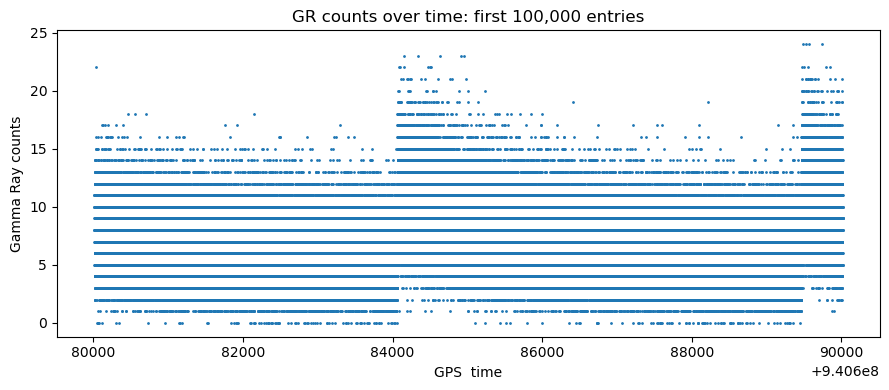

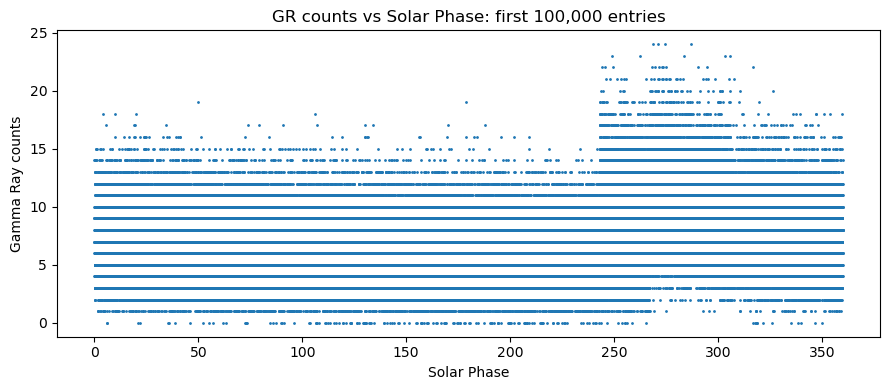

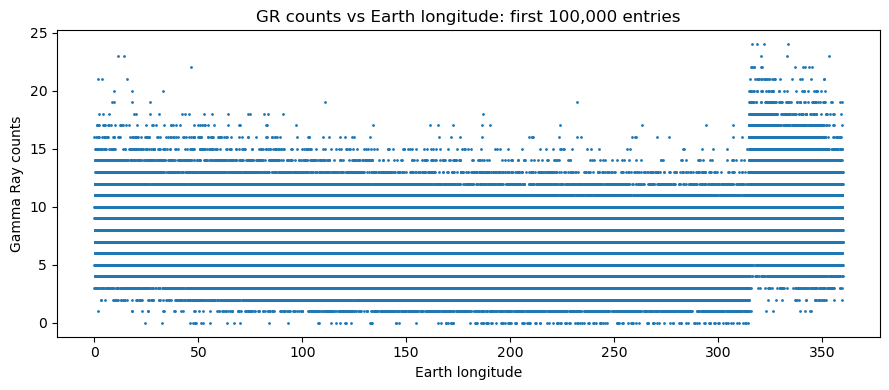

gamma ray incident rate seems to jump regularly - sunrise from satellite's POV?


In [61]:
# Examine the data 
# Goal: plot gamma ray counts vs time, solar phase, and Earth longitude 

# gr count vs time
plt.figure(figsize=(9, 4))

# scatter(horizontal coordinates, vertical coordinates, marker size)
plt.scatter(data[0][:100000], data[3][:100000] , s=1)

plt.xlabel("GPS  time")
plt.ylabel("Gamma Ray counts")
plt.title("GR counts over time: first 100,000 entries")
plt.tight_layout()
plt.show()


# gr count vs solar phase
plt.figure(figsize=(9, 4))

# scatter(horizontal coordinates, vertical coordinates, marker size)
plt.scatter(data[1][:100000], data[3][:100000] , s=1)

plt.xlabel("Solar Phase")
plt.ylabel("Gamma Ray counts")
plt.title("GR counts vs Solar Phase: first 100,000 entries")
plt.tight_layout()
plt.show()

# GR count vs Earth longitude
plt.figure(figsize=(9, 4))

# scatter(horizontal coordinates, vertical coordinates, marker size)
plt.scatter(data[2][:100000], data[3][:100000] , s=1)

plt.xlabel("Earth longitude")
plt.ylabel("Gamma Ray counts")
plt.title("GR counts vs Earth longitude: first 100,000 entries")
plt.tight_layout()
plt.show()

print("gamma ray incident rate seems to jump regularly - sunrise from satellite's POV?")

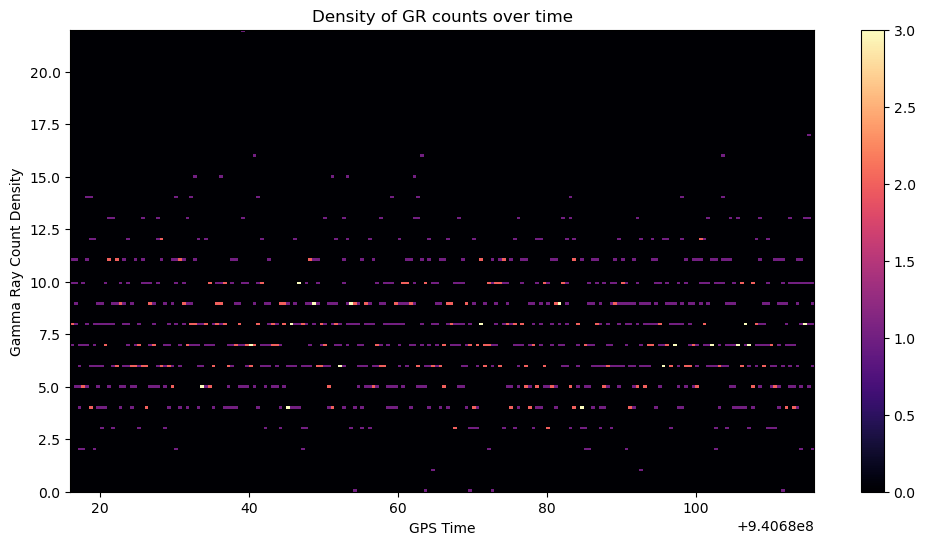

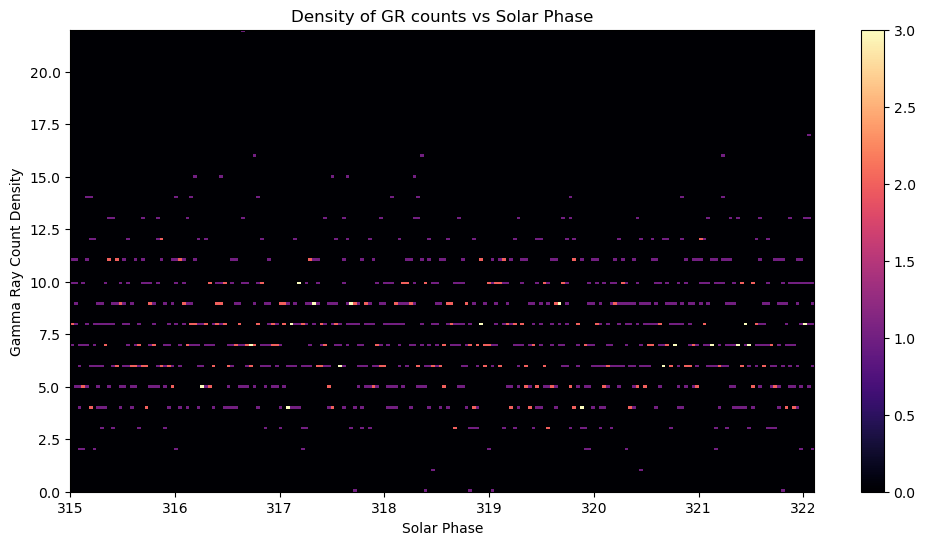

In [22]:
# 2D histogram Gamma Ray Count Density vs GPS Time

plt.figure(figsize=(12,6))

plt.hist2d(data[0][:1000], data[3][:1000], bins=200, cmap="magma");

plt.xlabel("GPS Time")
plt.ylabel("Gamma Ray Count Density")
plt.title("Density of GR counts over time")

plt.colorbar()
plt.show()

# 2D histogram Gamma Ray Count Density vs Solar Phase

plt.figure(figsize=(12,6))

plt.hist2d(data[1][:1000], data[3][:1000], bins=200, cmap="magma");

plt.xlabel("Solar Phase")
plt.ylabel("Gamma Ray Count Density")
plt.title("Density of GR counts vs Solar Phase")

plt.colorbar()
plt.show()



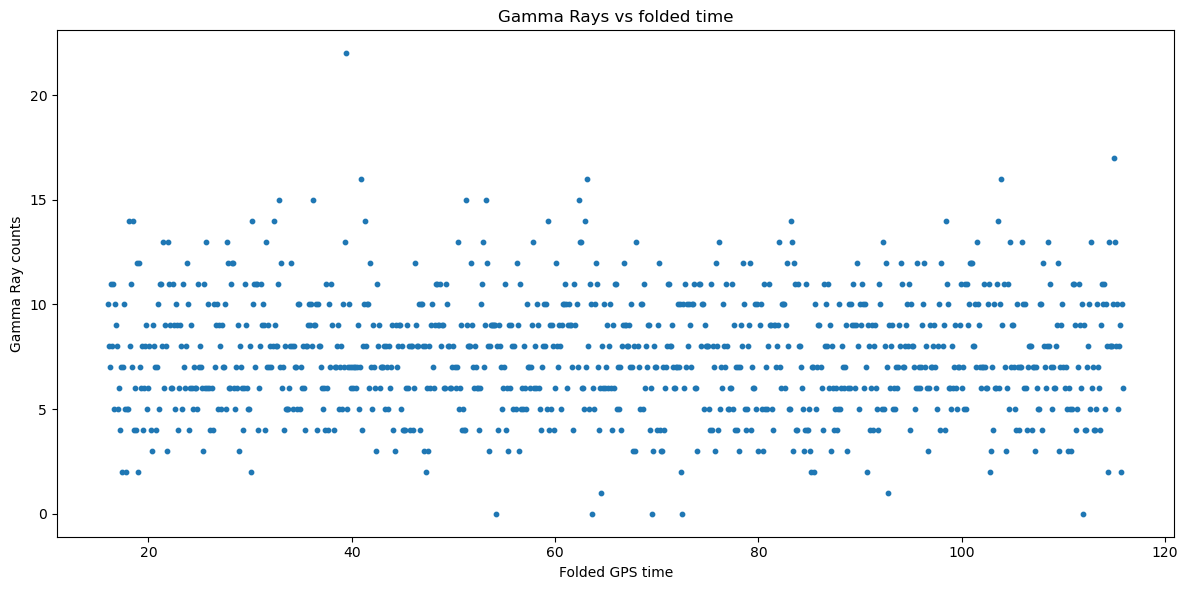

In [46]:
# fold GPS time as a periodic function 
# 90 minute orbit - data entry every 100 milliseconds -> 54,000 entries per orbit

fiveorbits = 54000
foldtime = data[0] % (fiveorbits)

# plot first 1000 points of folded time and GR counts
plt.figure(figsize=(12, 6))
plt.scatter(foldtime[:1000], data[3][:1000], s=10)
plt.xlabel("Folded GPS time")
plt.ylabel("Gamma Ray counts")
plt.title("Gamma Rays vs folded time")
plt.tight_layout()
plt.show()

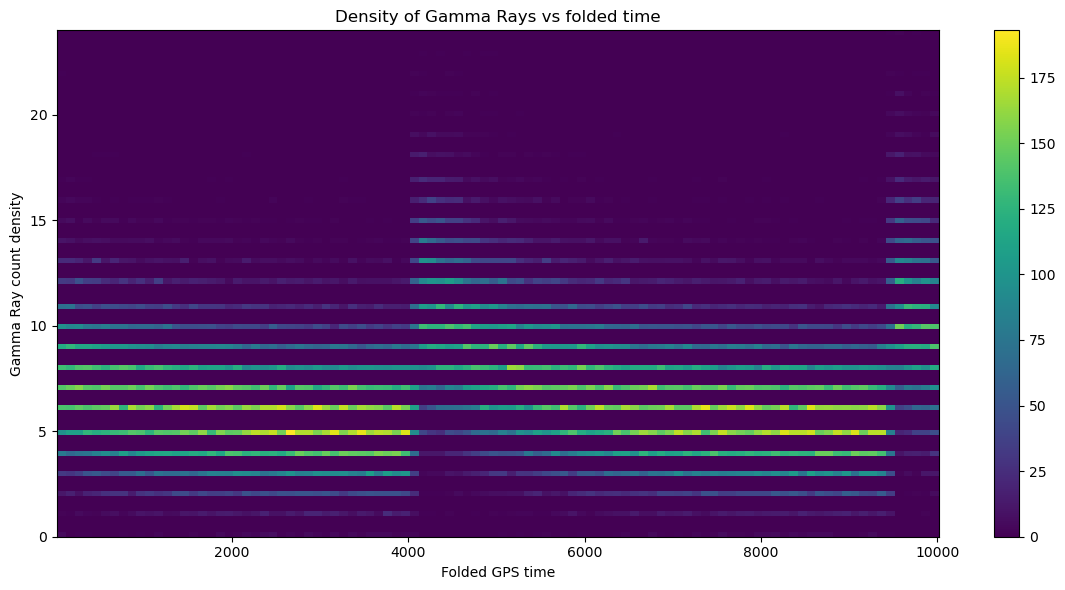

Here we go


In [59]:
#
plt.figure(figsize=(12, 6))
plt.hist2d(foldtime[:100000], data[3][:100000], bins=100, cmap='viridis')
plt.xlabel("Folded GPS time")
plt.ylabel("Gamma Ray count density")
plt.title("Density of Gamma Rays vs folded time")
plt.tight_layout()
plt.colorbar()
plt.show()
print("Here we go")

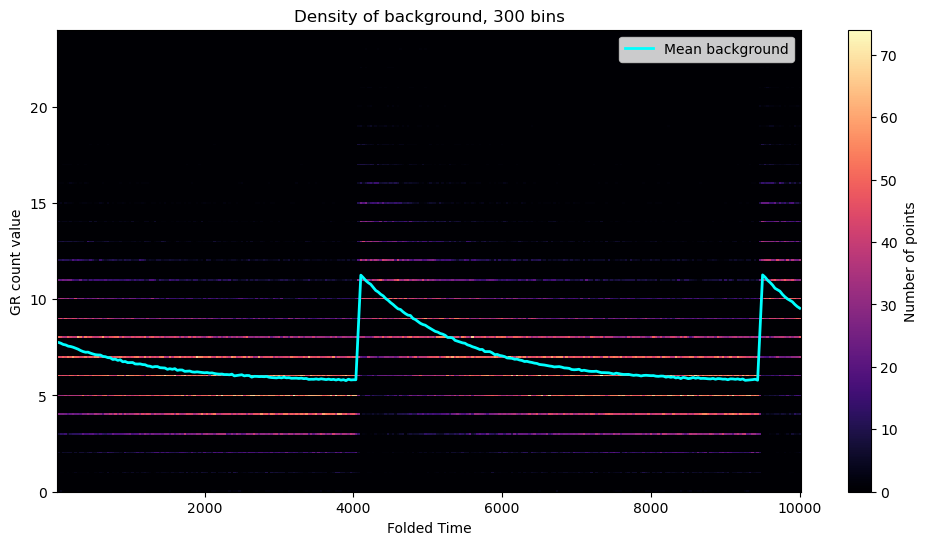

In [57]:
#3c
# create the 2D histogram
fig, ax = plt.subplots(figsize=(12, 6))

# hist, xedges, yedges, image - objects returned when calling ax.hist2d()
# writing them out as such is multiple assignment/ unpacking
hist, xedges, yedges, image = ax.hist2d(foldtime[:100000], data[3][:100000], bins=300, cmap="magma")

# calculate the mean background value in each folded-time bin
# stats.binned_statistic() returns 3 objects,
mean_bkgd, bin_edges, binnumber = stats.binned_statistic(foldtime, data[3], statistic="mean", bins=xedges)

# find the center of each folded-time bin 
# ( Final minus initial ) / 2
ft_centers = (xedges[:-1] + xedges[1:]) / 2

# overlay the mean background values as a line
ax.plot(ft_centers, mean_bkgd, color="cyan", linewidth=2, label="Mean background")

# labels for plot
ax.set_xlabel("Folded Time")
ax.set_ylabel("GR count value")
ax.set_title("Density of background, 300 bins")
ax.legend()

# color bar
fig.colorbar(image, ax=ax, label="Number of points")

plt.show()

### 1) discussion
#### The detector regularly sees a large jump in Gamma Ray counts. We believe this is because of Sol being regularly de-eclipsed by the Earth!
#### That is, the detector sees fewer Gamma Rays while on the night side of Earth. When it comes around and sees Sol again, a large jump in GR detection rate appears.

### 2) discussion 
#### There's a Poissonian distribution of  discrete counts that also exhibits an exponential decay behavior.
#### Gamma Ray detection is inherently Poissonian (not sure how to explain this more thoroughly - perhaps it would be more accurate to say that I don't feel confident that I can explain the meaning of this statement. I feel like I'm presenting a tautology - "It Is, Because It Is")
#### The exponential decay appears to follow the satellite's orbit cycle aka sunrise

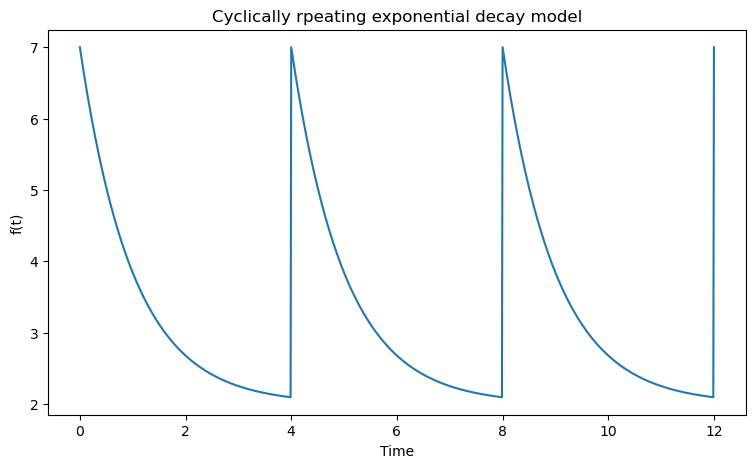

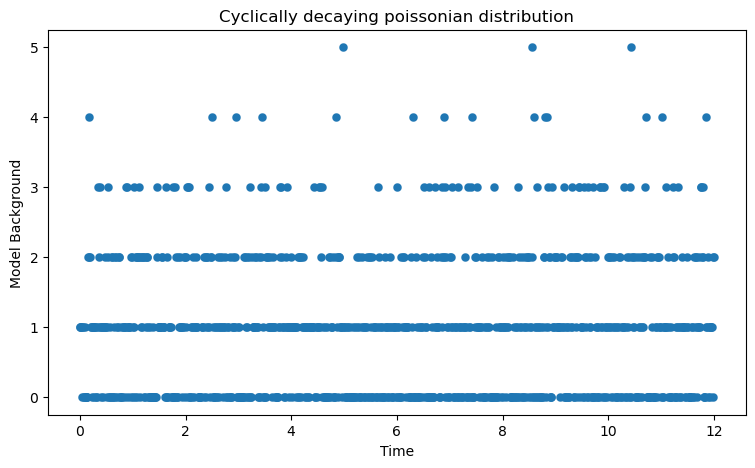

Not sure if this final step is workign the way I want it to - mostly because I don't know how to make the plot nicer to look at. I think it's working?


In [81]:
## 3) Model the background - taking inspiration from Homework 4 with a time varying distribution function
# start with exponential function of time
# parameters of the exponential time variance function
A = 5.0       # amplitude
k = 1.0       # exponential decay constant
T = 4.0       # period of repetition
C = 2.0       # positive vertical offset

# time space 0 to 12 in 1000 steps
t = np.linspace(0, 12, 1000)

# define the repeating exponential
f = A * np.exp(-k * (t % T)) + C

# plot 
plt.figure(figsize=(9, 5))
plt.plot(t, f)
plt.xlabel("Time")
plt.ylabel("f(t)")
plt.title("Cyclically rpeating exponential decay model")
plt.show()

# chuck it at the distribution function random variate thing
modelbkgd = stats.poisson.rvs(mu=1, loc=0, size = 1000)
plt.figure(figsize=(9,5))
plt.scatter(t, modelbkgd, linewidths = .1)
plt.xlabel("Time")
plt.ylabel("Model Background")
plt.title("Cyclically decaying poissonian distribution")
plt.show()

print("Not sure if this final step is workign the way I want it to - mostly because I don't know how to make the plot nicer to look at. I think it's working?")

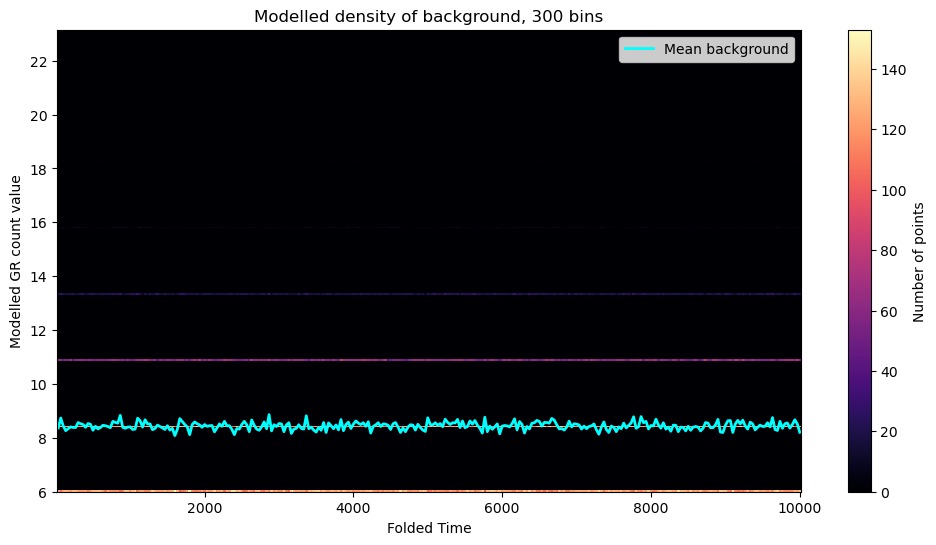

In [95]:
# molding model to data
# parameters of the exponential time variance function
amp = 5.0       # amplitude
k2 = 1.0       # exponential decay constant
per = 54000     # period of repetition
c = 6.0       # positive vertical offset

# define the repeating exponential
expon = amp * np.exp(-k2 * (foldtime % per)) + c

# define the model 
# goes up to 100000
model = stats.poisson.rvs(mu=1, loc=0, size = 100000)*np.sqrt(expon[:100000])+expon[:100000]


# create the 2D histogram
fig, ax = plt.subplots(figsize=(12, 6))
hist, xedges, yedges, image = ax.hist2d(foldtime[:100000], model[:100000], bins=300, cmap="magma")

# calculate the mean background value in each folded-time bin
mean_bkgd, bin_edges, binnumber = stats.binned_statistic(foldtime[:100000], model[:100000], statistic="mean", bins=xedges)

# find the center of each folded-time bin 
# ( Final minus initial ) / 2
ft_centers = (xedges[:-1] + xedges[1:]) / 2

# overlay the mean background values as a line
ax.plot(ft_centers, mean_bkgd, color="cyan", linewidth=2, label="Mean background")

# labels for plot
ax.set_xlabel("Folded Time")
ax.set_ylabel("Modelled GR count value")
ax.set_title("Modelled density of background, 300 bins")
ax.legend()

# color bar
fig.colorbar(image, ax=ax, label="Number of points")

plt.show()